## Import Libraries

In [60]:
# Run once in the notebook environment if packages are missing:
# %pip install -U pandas numpy matplotlib scikit-learn imbalanced-learn joblib
from pathlib import Path
import json
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline as SKPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize

SEED = 42

In [61]:
# from pathlib import Path
# import pandas as pd
# import matplotlib.pyplot as plt

# relative_path = Path("Data/Cleaned/reviews_cleaned.csv")
# source = next((root / relative_path for root in (Path.cwd(), *Path.cwd().parents)
#                if (root / relative_path).is_file()), None)
# if source is None:
#     raise FileNotFoundError(f"Run notebook 01 first: {relative_path}")

# df = pd.read_csv(source, encoding="utf-8-sig")


## Load Cleaned Data

In [62]:

import pandas as pd

# 1. Load cleaned dataset
df = pd.read_csv(
    "../Data/Cleaned/reviews_cleaned.csv",
    encoding="utf-8-sig"
)

# 2. Display dataset information
print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (2807, 3)


,Review,Attribute,Result
0,الاكل كان مناسب والسانويش كان لذيذ,المأكولات,ايجابي
1,منيو الطعام سيء,المأكولات,سلبي
2,المأكولات من سندويش وحلا كان طيب عموما الاكل طيب,المأكولات,ايجابي
3,افضل دونات تبدا فيها يومك,المأكولات,ايجابي
4,خيار ممتاز للقهوه,المشروبات,ايجابي


## Define Features and Targets

In [63]:
X = df["Review"].astype(str)
y_result = df["Result"].astype(str)
y_attribute = df["Attribute"].astype(str)
print("Feature:", X.name)
print("Sentiment target:", y_result.name, "classes:", sorted(y_result.unique()))
print("Topic target:", y_attribute.name, "classes:", sorted(y_attribute.unique()))

Feature: Review
Sentiment target: Result classes: ['ايجابي', 'سلبي', 'محايد']
Topic target: Attribute classes: ['الاسعار', 'الجلسات', 'الخدمة', 'المأكولات', 'المشروبات']


## Train/Test Split

In [64]:

from sklearn.model_selection import GroupShuffleSplit

# 1. Define Features and Targets
X = df["Review"].astype(str)
y_result = df["Result"].astype(str)
y_attribute = df["Attribute"].astype(str)

# 2. Group identical reviews to prevent Data Leakage
groups = (
    X.str.strip()
     .str.replace(r"\s+", " ", regex=True)
     .str.casefold()
)

# 3. Split data into 80% Training and 20% Testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, groups=groups)
)

# 4. Split Features
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# 5. Split Targets
y_train = {
    "Result": y_result.iloc[train_idx],
    "Attribute": y_attribute.iloc[train_idx]
}

y_test = {
    "Result": y_result.iloc[test_idx],
    "Attribute": y_attribute.iloc[test_idx]
}

# 6. Define Training Groups for Cross-Validation
g_train = groups.iloc[train_idx]

# 7. Display Results
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
for target in y_train:
    print(f"\n{target}")
    print(y_train[target].value_counts())

print("\nTesting class distribution:")
for target in y_test:
    print(f"\n{target}")
    print(y_test[target].value_counts())

# 8. Check for Data Leakage
assert set(g_train).isdisjoint(set(groups.iloc[test_idx]))

print("\nNo identical reviews shared between Train and Test.")


Training samples: 2243
Testing samples: 564

Training class distribution:

Result
Result
ايجابي    1442
سلبي       600
محايد      201
Name: count, dtype: int64

Attribute
Attribute
المشروبات    720
الخدمة       532
الجلسات      400
المأكولات    335
الاسعار      256
Name: count, dtype: int64

Testing class distribution:

Result
Result
ايجابي    352
سلبي      150
محايد      62
Name: count, dtype: int64

Attribute
Attribute
المشروبات    174
الجلسات      117
الخدمة       116
المأكولات     87
الاسعار       70
Name: count, dtype: int64

No identical reviews shared between Train and Test.


## Check Class Imbalance


Train — Result


,Count,Percent
Class,,
ايجابي,1442,64.29
سلبي,600,26.75
محايد,201,8.96


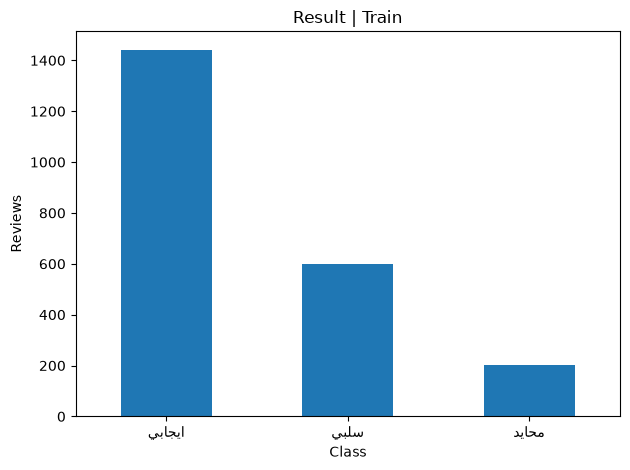


Test (untouched) — Result


,Count,Percent
Class,,
ايجابي,352,62.41
سلبي,150,26.60
محايد,62,10.99


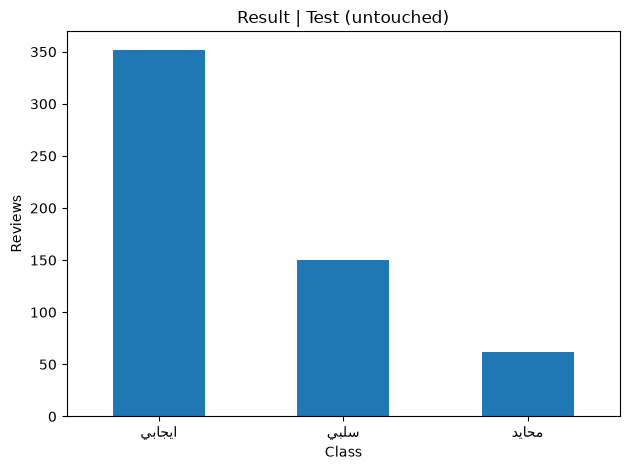


Train — Attribute


,Count,Percent
Class,,
المشروبات,720,32.10
الخدمة,532,23.72
الجلسات,400,17.83
المأكولات,335,14.94
الاسعار,256,11.41


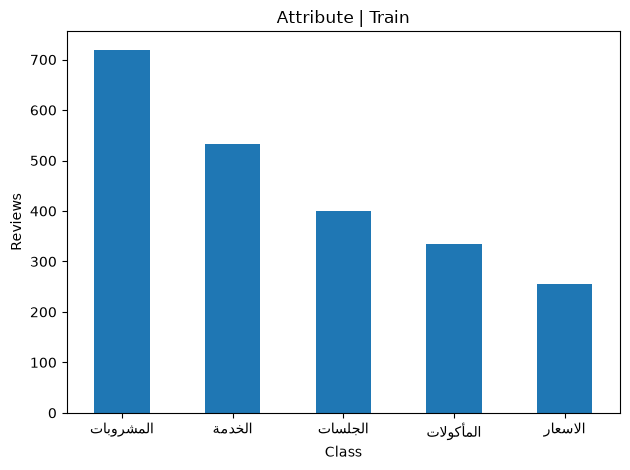


Test (untouched) — Attribute


,Count,Percent
Class,,
المشروبات,174,30.85
الجلسات,117,20.74
الخدمة,116,20.57
المأكولات,87,15.43
الاسعار,70,12.41


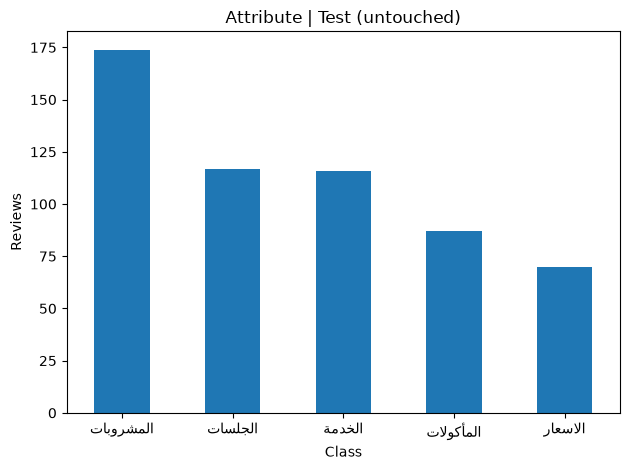

In [65]:
def distribution_table(target, split):
    counts = target.value_counts().rename("Count")
    percent = (target.value_counts(normalize=True).mul(100).round(2)).rename("Percent")
    result = pd.concat([counts, percent], axis=1)
    result.index.name = "Class"
    print(f"\n{split} — {target.name}")
    display(result)
    ax = result["Count"].plot.bar(title=f"{target.name} | {split}", rot=0)
    ax.set_ylabel("Reviews")
    plt.tight_layout()
    plt.show()

for target in ("Result", "Attribute"):
    distribution_table(y_train[target], "Train")
    distribution_table(y_test[target], "Test (untouched)")

## Baseline Model — بدون معالجة Imbalance

In [66]:
def make_cv(y, group_values, folds=5):
    per_class_groups = (
        pd.DataFrame({"label": y.to_numpy(), "group": group_values.to_numpy()})
        .groupby("label")["group"].nunique()
    )
    if per_class_groups.min() < folds:
        raise ValueError(
            f"At least {folds} distinct review groups per class are required.\n"
            f"Groups per class:\n{per_class_groups}"
        )
    return StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=SEED)

cv_by_target = {target: make_cv(y_train[target], g_train) for target in y_train}

scorers = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "precision_micro": "precision_micro",
    "recall_micro": "recall_micro",
    "f1_micro": "f1_micro",
}

baseline_cv = {}
for target in ("Result", "Attribute"):
    baseline = SKPipeline([
        ("tfidf", TfidfVectorizer(sublinear_tf=True)),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED))
    ])
    scores = cross_validate(
        baseline, X_train, y_train[target], groups=g_train,
        cv=cv_by_target[target], scoring=scorers, n_jobs=-1,
        error_score="raise"
    )
    baseline_cv[target] = {name: float(np.mean(scores[f"test_{name}"])) for name in scorers}
    print(f"\n===== Baseline Logistic Regression | {target} (CV only) =====")
    display(pd.DataFrame.from_dict(baseline_cv[target], orient="index", columns=["Mean CV Score"]).round(4))


===== Baseline Logistic Regression | Result (CV only) =====


,Mean CV Score
accuracy,0.7650
precision_macro,0.6705
recall_macro,0.5155
f1_macro,0.5210
precision_micro,0.7650
recall_micro,0.7650
f1_micro,0.7650



===== Baseline Logistic Regression | Attribute (CV only) =====


,Mean CV Score
accuracy,0.8150
precision_macro,0.8651
recall_macro,0.7798
f1_macro,0.8084
precision_micro,0.8150
recall_micro,0.8150
f1_micro,0.8150


## Handle Imbalance + Multiple Models + Hyperparameter Tuning

In [67]:
def build_search(y, cv):
    pipe = ImbPipeline(steps=[
        ("tfidf", TfidfVectorizer(sublinear_tf=True)),
        ("sampler", "passthrough"),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED))
    ])
    grid = [
        {"tfidf__ngram_range": [(1,1), (1,2)],
         "tfidf__min_df": [1],
         "sampler": ["passthrough", RandomOverSampler(random_state=SEED)],
         "model": [LogisticRegression(max_iter=2000, random_state=SEED)],
         "model__C": [0.5, 2.0], "model__class_weight": [None, "balanced"]},
        {"tfidf__ngram_range": [(1,1), (1,2)],
         "tfidf__min_df": [1],
         "sampler": ["passthrough", RandomOverSampler(random_state=SEED)],
         "model": [LinearSVC(random_state=SEED, max_iter=4000)],
         "model__C": [0.5, 2.0], "model__class_weight": [None, "balanced"]},
        {"tfidf__ngram_range": [(1,1), (1,2)],
         "tfidf__min_df": [1],
         "sampler": ["passthrough", RandomOverSampler(random_state=SEED)],
         "model": [ComplementNB()], "model__alpha": [0.5, 1.0]},
    ]
    return GridSearchCV(pipe, grid, cv=cv, scoring={
        "macro_f1": "f1_macro", "micro_f1": "f1_micro", "accuracy": "accuracy"
    }, refit="macro_f1", n_jobs=-1, verbose=1, error_score="raise", return_train_score=False)

searches = {}
for target in ("Result", "Attribute"):
    print("\n========== Tuning:", target, "==========")
    s = build_search(y_train[target], cv_by_target[target])
    s.fit(X_train, y_train[target], groups=g_train)
    searches[target] = s
    print("Best CV Macro F1:", round(s.best_score_, 4))
    print("Best parameters:", s.best_params_)


========== Tuning: Result ==========
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best CV Macro F1: 0.6621
Best parameters: {'model': LogisticRegression(max_iter=2000, random_state=42), 'model__C': 2.0, 'model__class_weight': 'balanced', 'sampler': 'passthrough', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}

========== Tuning: Attribute ==========
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best CV Macro F1: 0.86
Best parameters: {'model': ComplementNB(), 'model__alpha': 1.0, 'sampler': 'passthrough', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}


## Compare CV Results

In [68]:
for target, search in searches.items():
    cv_results = pd.DataFrame(search.cv_results_)
    cols = ["rank_test_macro_f1", "mean_test_macro_f1", "mean_test_micro_f1",
            "mean_test_accuracy", "param_model", "param_sampler", "params"]
    print("\nTop tuned candidates:", target)
    display(cv_results.sort_values("rank_test_macro_f1")[cols].head(10))

    best_row = cv_results.loc[search.best_index_]
    comparison = pd.DataFrame([
        {"Approach": "Baseline Logistic Regression (no balance)",
         "CV Macro F1": baseline_cv[target]["f1_macro"],
         "CV Micro F1": baseline_cv[target]["f1_micro"],
         "CV Accuracy": baseline_cv[target]["accuracy"]},
        {"Approach": "Best model + tuning (balance optional)",
         "CV Macro F1": float(best_row["mean_test_macro_f1"]),
         "CV Micro F1": float(best_row["mean_test_micro_f1"]),
         "CV Accuracy": float(best_row["mean_test_accuracy"])}
    ])
    print("Baseline vs Tuned —", target)
    display(comparison.round(4))


Top tuned candidates: Result


,rank_test_macro_f1,mean_test_macro_f1,mean_test_micro_f1,mean_test_accuracy,param_model,param_sampler,params
12,1,0.662143,0.782870,0.782870,"LogisticRegression(max_iter=2000, random_state...",passthrough,"{'model': LogisticRegression(max_iter=2000, ra..."
2,2,0.661964,0.777966,0.777966,"LogisticRegression(max_iter=2000, random_state...",RandomOverSampler(random_state=42),"{'model': LogisticRegression(max_iter=2000, ra..."
6,2,0.661964,0.777966,0.777966,"LogisticRegression(max_iter=2000, random_state...",RandomOverSampler(random_state=42),"{'model': LogisticRegression(max_iter=2000, ra..."
7,4,0.660177,0.785102,0.785102,"LogisticRegression(max_iter=2000, random_state...",RandomOverSampler(random_state=42),"{'model': LogisticRegression(max_iter=2000, ra..."
3,4,0.660177,0.785102,0.785102,"LogisticRegression(max_iter=2000, random_state...",RandomOverSampler(random_state=42),"{'model': LogisticRegression(max_iter=2000, ra..."
13,6,0.660170,0.789562,0.789562,"LogisticRegression(max_iter=2000, random_state...",passthrough,"{'model': LogisticRegression(max_iter=2000, ra..."
14,7,0.659263,0.783314,0.783314,"LogisticRegression(max_iter=2000, random_state...",RandomOverSampler(random_state=42),"{'model': LogisticRegression(max_iter=2000, ra..."
10,7,0.659263,0.783314,0.783314,"LogisticRegression(max_iter=2000, random_state...",RandomOverSampler(random_state=42),"{'model': LogisticRegression(max_iter=2000, ra..."
4,9,0.657451,0.769052,0.769052,"LogisticRegression(max_iter=2000, random_state...",passthrough,"{'model': LogisticRegression(max_iter=2000, ra..."
5,10,0.655273,0.776186,0.776186,"LogisticRegression(max_iter=2000, random_state...",passthrough,"{'model': LogisticRegression(max_iter=2000, ra..."


Baseline vs Tuned — Result


,Approach,CV Macro F1,CV Micro F1,CV Accuracy
0,Baseline Logistic Regression (no balance),0.5210,0.7650,0.7650
1,Best model + tuning (balance optional),0.6621,0.7829,0.7829



Top tuned candidates: Attribute


,rank_test_macro_f1,mean_test_macro_f1,mean_test_micro_f1,mean_test_accuracy,param_model,param_sampler,params
36,1,0.860033,0.859568,0.859568,ComplementNB(),passthrough,"{'model': ComplementNB(), 'model__alpha': 1.0,..."
24,2,0.858814,0.857335,0.857335,"LinearSVC(max_iter=4000, random_state=42)",passthrough,"{'model': LinearSVC(max_iter=4000, random_stat..."
22,3,0.857718,0.856442,0.856442,"LinearSVC(max_iter=4000, random_state=42)",RandomOverSampler(random_state=42),"{'model': LinearSVC(max_iter=4000, random_stat..."
18,3,0.857718,0.856442,0.856442,"LinearSVC(max_iter=4000, random_state=42)",RandomOverSampler(random_state=42),"{'model': LinearSVC(max_iter=4000, random_stat..."
32,5,0.857646,0.857335,0.857335,ComplementNB(),passthrough,"{'model': ComplementNB(), 'model__alpha': 0.5,..."
28,6,0.856712,0.855552,0.855552,"LinearSVC(max_iter=4000, random_state=42)",passthrough,"{'model': LinearSVC(max_iter=4000, random_stat..."
20,7,0.856572,0.854655,0.854655,"LinearSVC(max_iter=4000, random_state=42)",passthrough,"{'model': LinearSVC(max_iter=4000, random_stat..."
16,8,0.856177,0.855108,0.855108,"LinearSVC(max_iter=4000, random_state=42)",passthrough,"{'model': LinearSVC(max_iter=4000, random_stat..."
30,9,0.854127,0.853321,0.853321,"LinearSVC(max_iter=4000, random_state=42)",RandomOverSampler(random_state=42),"{'model': LinearSVC(max_iter=4000, random_stat..."
26,9,0.854127,0.853321,0.853321,"LinearSVC(max_iter=4000, random_state=42)",RandomOverSampler(random_state=42),"{'model': LinearSVC(max_iter=4000, random_stat..."


Baseline vs Tuned — Attribute


,Approach,CV Macro F1,CV Micro F1,CV Accuracy
0,Baseline Logistic Regression (no balance),0.8084,0.8150,0.8150
1,Best model + tuning (balance optional),0.8600,0.8596,0.8596


## Evaluate once on Test Set


========== TEST: Result ==========


,Value
accuracy,0.785461
precision_macro,0.695331
recall_macro,0.677500
f1_macro,0.683888
precision_micro,0.785461
recall_micro,0.785461
f1_micro,0.785461


Macro / Micro (explicit):


,Averaging,Precision,Recall,F1
0,Macro,0.6953,0.6775,0.6839
1,Micro,0.7855,0.7855,0.7855


Classification Report (per class):
              precision    recall  f1-score   support

      ايجابي       0.86      0.87      0.87       352
        سلبي       0.69      0.75      0.72       150
       محايد       0.53      0.42      0.47        62

    accuracy                           0.79       564
   macro avg       0.70      0.68      0.68       564
weighted avg       0.78      0.79      0.78       564



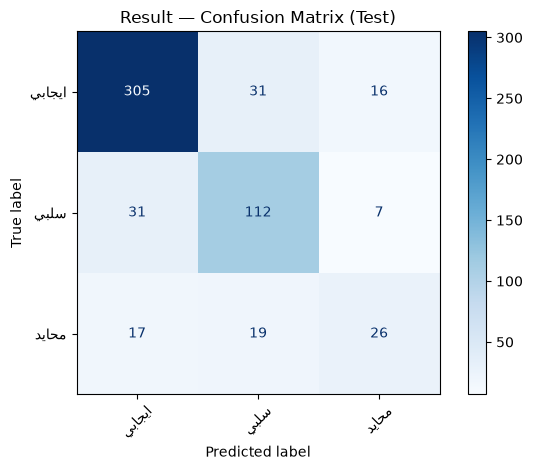


========== TEST: Attribute ==========


,Value
accuracy,0.859929
precision_macro,0.866957
recall_macro,0.853856
f1_macro,0.858605
precision_micro,0.859929
recall_micro,0.859929
f1_micro,0.859929


Macro / Micro (explicit):


,Averaging,Precision,Recall,F1
0,Macro,0.8670,0.8539,0.8586
1,Micro,0.8599,0.8599,0.8599


Classification Report (per class):
              precision    recall  f1-score   support

     الاسعار       0.89      0.91      0.90        70
     الجلسات       0.83      0.82      0.83       117
      الخدمة       0.79      0.83      0.81       116
   المأكولات       0.94      0.78      0.86        87
   المشروبات       0.88      0.93      0.90       174

    accuracy                           0.86       564
   macro avg       0.87      0.85      0.86       564
weighted avg       0.86      0.86      0.86       564



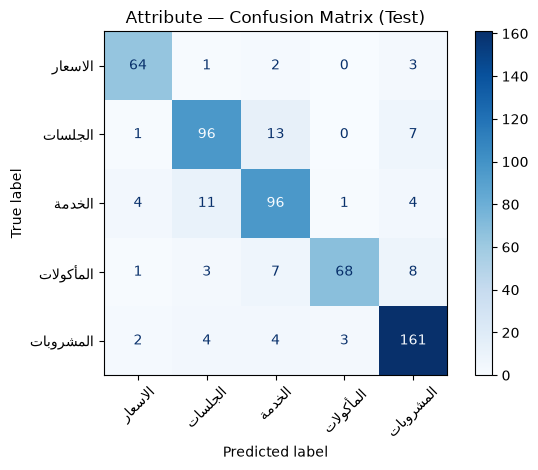

In [69]:
reports = {}
for target, search in searches.items():
    y_true = y_test[target]
    y_pred = search.best_estimator_.predict(X_test)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_micro": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "recall_micro": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "f1_micro": f1_score(y_true, y_pred, average="micro", zero_division=0),
    }
    reports[target] = {"metrics": metrics, "classification_report": classification_report(y_true, y_pred, output_dict=True, zero_division=0)}
    print("\n========== TEST:", target, "==========")
    display(pd.DataFrame([metrics]).T.rename(columns={0: "Value"}))
    print("Macro / Micro (explicit):")
    display(pd.DataFrame({
        "Averaging": ["Macro", "Micro"],
        "Precision": [metrics["precision_macro"], metrics["precision_micro"]],
        "Recall": [metrics["recall_macro"], metrics["recall_micro"]],
        "F1": [metrics["f1_macro"], metrics["f1_micro"]]
    }).round(4))
    print("Classification Report (per class):")
    print(classification_report(y_true, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, xticks_rotation=45, cmap="Blues")
    plt.title(f"{target} — Confusion Matrix (Test)")
    plt.tight_layout()
    plt.show()

## ROC Curve + AUC (One-vs-Rest)

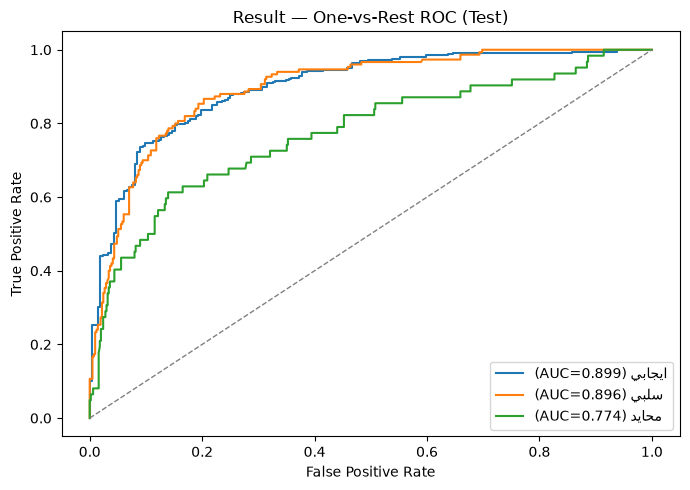

Macro OvR AUC (unweighted mean): 0.8563


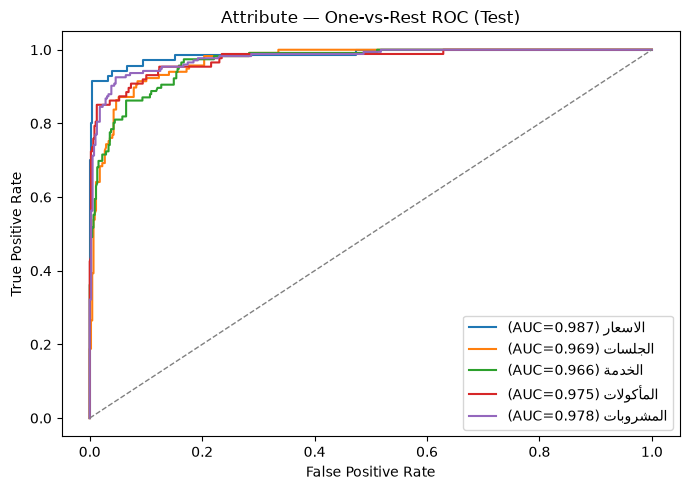

Macro OvR AUC (unweighted mean): 0.9751


In [70]:
def plot_ovr_roc(model, X_values, y_true, target):
    classes = model.classes_
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_values)
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_values)
    else:
        print(target, ": No score/probability method; ROC unavailable")
        return {}
    scores = np.asarray(scores)
    if scores.ndim == 1:  # binary decision scores
        scores = np.column_stack([-scores, scores])
    if scores.shape[1] != len(classes):
        print(target, ": Score shape incompatible with classes")
        return {}
    area_per_class = {}
    y_arr = np.asarray(y_true)
    plt.figure(figsize=(7, 5))
    for i, label in enumerate(classes):
        binary_true = (y_arr == label).astype(int)
        if len(np.unique(binary_true)) != 2:
            print("Skipping class without both positive and negative test samples:", label)
            continue
        fpr, tpr, _ = roc_curve(binary_true, scores[:, i])
        class_auc = float(auc(fpr, tpr))
        area_per_class[str(label)] = class_auc
        plt.plot(fpr, tpr, label=f"{label} (AUC={class_auc:.3f})")
    plt.plot([0,1], [0,1], "--", color="gray", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{target} — One-vs-Rest ROC (Test)")
    plt.legend()
    plt.tight_layout()
    plt.show()
    if area_per_class:
        print("Macro OvR AUC (unweighted mean):", round(float(np.mean(list(area_per_class.values()))), 4))
    return area_per_class

for target, search in searches.items():
    reports[target]["roc_auc_ovr_by_class"] = plot_ovr_roc(search.best_estimator_, X_test, y_test[target], target)

## Did Imbalance Handling Help?

In [71]:
for target, search in searches.items():
    table = pd.DataFrame(search.cv_results_)
    table["oversampling"] = table["param_sampler"].astype(str).ne("passthrough")
    summary = (table.groupby("oversampling", as_index=False)
              .agg(best_cv_macro_f1=("mean_test_macro_f1", "max"),
                   best_cv_micro_f1=("mean_test_micro_f1", "max")))
    print("\n", target, "CV comparison (oversampling vs no oversampling)")
    display(summary)
    print("Best selected sampler:", search.best_params_["sampler"])
    print("Best selected class weight:", search.best_params_.get("model__class_weight", "not applicable"))


 Result CV comparison (oversampling vs no oversampling)


,oversampling,best_cv_macro_f1,best_cv_micro_f1
0,False,0.662143,0.798033
1,True,0.661964,0.791790


Best selected sampler: passthrough
Best selected class weight: balanced

 Attribute CV comparison (oversampling vs no oversampling)


,oversampling,best_cv_macro_f1,best_cv_micro_f1
0,False,0.860033,0.859568
1,True,0.857718,0.856442


Best selected sampler: passthrough
Best selected class weight: not applicable


In [ ]:
Overfitting Check

from sklearn.metrics import f1_score

for target in ["Result", "Attribute"]:

    model = searches[target].best_estimator_

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_f1 = f1_score(
        y_train[target], train_pred, average="macro"
    )

    test_f1 = f1_score(
        y_test[target], test_pred, average="macro"
    )

    print(f"\n{target}")
    print("Train Macro F1:", round(train_f1, 3))
    print("Test Macro F1:", round(test_f1, 3))
    print("Gap:", round(train_f1 - test_f1, 3))

## Save Models + Evaluation Reports

In [73]:
from pathlib import Path

project_root = Path(
    r"C:\Users\engza\OneDrive\Desktop\Project2"
)
model_dir = project_root / "Models"
report_dir = project_root / "Reports"
model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)
paths = {"Result": model_dir / "sentiment_pipeline.joblib",
         "Attribute": model_dir / "topic_pipeline.joblib"}
for target, path in paths.items():
    joblib.dump(searches[target].best_estimator_, path)
    print("Saved:", path)
with open(report_dir / "evaluation.json", "w", encoding="utf-8") as f:
    json.dump(reports, f, ensure_ascii=False, indent=2)
print("Saved:", report_dir / "evaluation.json")

Saved: C:\Users\engza\OneDrive\Desktop\Project2\Models\sentiment_pipeline.joblib
Saved: C:\Users\engza\OneDrive\Desktop\Project2\Models\topic_pipeline.joblib
Saved: C:\Users\engza\OneDrive\Desktop\Project2\Reports\evaluation.json
